<a href="https://colab.research.google.com/github/alexlimatds/esp_introducao_am/blob/main/05_classificacao_com_arvores_de_decisao.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Classificação com Árvores de Decisão

## Introdução

Árvores de decisão são modelos de aprendizado de máquina supervisionado que se destacam pela interpretabilidade e pela capacidade de lidar com diferentes tipos de dados. Em essência, uma árvore de decisão é um fluxograma hierárquico onde cada nó interno representa um teste sobre um atributo, cada ramo corresponde ao resultado do teste, e cada nó folha contém a predição final (o rótulo da classe) .

O processo de inferência é intuitivo: um exemplo percorre a árvore da raiz até uma folha, respondendo às perguntas em cada nó. Por exemplo, para classificar um animal, a árvore pode perguntar: "O animal tem mais de 3 pernas?" Se sim, segue para um ramo; se não, para outro. Ao final, a folha alcançada fornece a classificação .

**Principais características:**
- **Interpretabilidade**: As regras aprendidas podem ser visualizadas e compreendidas por humanos, o que é valioso em áreas como saúde e finanças .
- **Estrutura hierárquica**: Permite capturar interações não-lineares entre atributos sem necessidade de especificação manual.
- **Flexibilidade**: Podem lidar com atributos numéricos e categóricos, embora com algumas ressalvas (discutidas adiante).

**Exemplo prático: Classificação de Medalhistas Olímpicos**

A imagem a seguir ilustra uma árvore de decisão treinada para prever se um atleta ganhou uma medalha com base em Peso e Idade :

```
                          [Idade < 24?]
                         /             \
                    (Sim)               (Não)
                     /                     \
            [Peso < 65?]                [Peso > 70?]
           /          \               /          \
      (Sim)         (Não)        (Sim)         (Não)
        |              |            |              |
    Não Ganhou    Ganhou      Ganhou        Não Ganhou
```

Neste exemplo, a árvore primeiro pergunta se a idade é menor que 24. Se sim, verifica o peso; se não, verifica se o peso é maior que 70. As folhas indicam a predição (ganhou ou não ganhou medalha). Note que a árvore pode ser lida como um conjunto de regras `se-então`.

**Vantagens e Desvantagens**

Vantagens:

- Fácil interpretação e visualização;
- Não requer normalização ou padronização de dados;
- Lida com atributos numéricos e categóricos;
- É capaz de capturar interações não-lineares;
- Rápida no momento da predição.

Desvantagens:
- Tendência ao sobreajuste (overfitting), especialmente em árvores profundas;
- Instabilidade: pequenas variações nos dados podem gerar árvores muito diferentes;
- É sensível a conjuntos de dados desbalanceados.

O sobreajuste é o principal desafio: sem controle de complexidade, a árvore pode memorizar o conjunto de treinamento e perder capacidade de generalização .



## Processo de Geração de uma Árvore

A construção de uma árvore de decisão segue uma estratégia gulosa e recursiva. O objetivo em cada nó é escolher o atributo que melhor separa os exemplos em subconjuntos mais "puros" — ou seja, subconjuntos onde uma classe predomina.

### Medidas de Impureza

Para quantificar a qualidade de uma divisão, utilizam-se medidas de impureza. As duas mais comuns são **Entropia** e **Índice de Gini**.

**Entropia**

A entropia mede o grau de incerteza ou desordem em um conjunto de dados. Seja $S$ um conjunto de observações (instâncias) e $p_i$ a probabilidade de ocorrência de uma observação da classe $i$, a entropia é dada por:

$$Entropia(S) = -\sum_{i=1}^{c} p_i \log_2(p_i)$$

Onde $c$ é o número de classes. A entropia é máxima quando as classes estão igualmente distribuídas (máxima incerteza) e mínima (zero) quando todos os exemplos pertencem a uma única classe .

**Índice de Gini**

O índice de Gini é uma medida alternativa de impureza, computacionalmente mais eficiente que a entropia:

$$Gini(S) = 1 - \sum_{i=1}^{c} p_i^2$$

Assim como a entropia, o Gini é zero para conjuntos puros e atinge seu valor máximo quando as classes estão uniformemente distribuídas.

### Ganho de Informação

O **Ganho de Informação** quantifica a redução esperada na impureza ao dividir o conjunto $S$ pelo atributo $A$. Para um atributo com $v$ valores distintos, o ganho é:

$$Ganho(S, A) = Entropia(S) - \sum_{j=1}^{v} \frac{|S_j|}{|S|} Entropia(S_j)$$

Onde $S_j$ é o subconjunto de $S$ onde o atributo $A$ assume o valor $j$. O algoritmo escolhe o atributo que maximiza o ganho de informação em cada nó.

### Partição de Atributos

Para **atributos categóricos**, cada valor distinto gera um teste binário. Para **atributos numéricos**, o algoritmo testa pontos de corte: ordena os valores e avalia divisões binárias da forma $A \leq v$. O ponto de corte ótimo é aquele que maximiza o ganho de informação .

### Exemplo Numérico Passo a Passo

Para consolidar os conceitos, considere um pequeno conjunto de dados sobre condições para jogar tênis, com 10 exemplos e duas classes: **Sim** (jogar) e **Não** (não jogar).

| # | Tempo | Umidade | Jogar? |
|---|-------|---------|--------|
| 1 | Sol | Alta | Não |
| 2 | Sol | Alta | Não |
| 3 | Nublado | Alta | Sim |
| 4 | Chuva | Normal | Sim |
| 5 | Chuva | Normal | Não |
| 6 | Chuva | Normal | Sim |
| 7 | Nublado | Normal | Sim |
| 8 | Sol | Alta | Não |
| 9 | Sol | Normal | Sim |
| 10 | Chuva | Normal | Sim |

**Passo 1 — Entropia do conjunto raiz $S$**

Das 10 amostras, 6 são "Sim" e 4 são "Não". Logo:

$$p_{Sim} = \frac{6}{10} = 0{,}6$$

$$p_{Não} = \frac{4}{10} = 0{,}4$$

$$Entropia(S) = -\left(0{,}6 \log_2 0{,}6 + 0{,}4 \log_2 0{,}4\right)$$

Calculando os logaritmos: $\log_2 0{,}6 \approx -0{,}737$ e $\log_2 0{,}4 \approx -1{,}322$.

$$Entropia(S) = -\left(0{,}6 \cdot (-0{,}737) + 0{,}4 \cdot (-1{,}322)\right) = 0{,}971$$

**Passo 2 — Avaliar a divisão pelo atributo "Tempo"**

O atributo Tempo tem três valores: Sol, Nublado e Chuva.

- **Sol** (amostras 1, 2, 8, 9): 1 Sim, 3 Não:

$$p_{Sim} = \frac{1}{4} =0{,}25$$

$$p_{Não} = \frac{3}{4} =0{,}75$$

  $$Entropia(Sol) = -\left(0{,}25 \log_2 0{,}25 + 0{,}75 \log_2 0{,}75\right) = -((-2) \cdot 0{,}25 + (-0{,}415) \cdot 0{,}75) = 0{,}811$$

- **Nublado** (amostras 3, 7): 2 Sim, 0 Não (conjunto puro):
  
  $$Entropia(Nublado) = 0$$

- **Chuva** (amostras 4, 5, 6, 10): 3 Sim, 1 Não:

$$p_{Sim} = \frac{3}{4} = 0{,}75$$

$$p_{Não} = \frac{1}{4} = 0{,}25$$

  $$Entropia(Chuva) = 0{,}811$$

Entropia ponderada após a divisão:

$$Entropia(S, Tempo) = \frac{4}{10}(0{,}811) + \frac{2}{10}(0) + \frac{4}{10}(0{,}811) = 0{,}324 + 0 + 0{,}324 = 0{,}649$$

Ganho de informação:

$$Ganho(S, Tempo) = 0{,}971 - 0{,}649 = 0{,}322$$

**Passo 3 — Avaliar a divisão pelo atributo "Umidade"**

Umidade tem dois valores: Alta e Normal.

- **Alta** (amostras 1, 2, 3, 8): 1 Sim, 3 Não:

$$p_{Sim} = \frac{1}{4} = 0{,}25$$

$$p_{Não} = \frac{3}{4} = 0{,}75$$

$$Entropia(Alta) = 0{,}811$$

- **Normal** (amostras 4, 5, 6, 7, 9, 10): 5 Sim, 1 Não:

$$p_{Sim} = \frac{5}{6} = 0{,}833$$

$$p_{Não} = \frac{1}{6} = 0{,}167$$

  $$Entropia(Normal) = -\left(0{,}833 \log_2 0{,}833 + 0{,}167 \log_2 0{,}167\right) = 0{,}650$$

Entropia ponderada:

$$Entropia(S, Umidade) = \frac{4}{10}(0{,}811) + \frac{6}{10}(0{,}650) = 0{,}324 + 0{,}390 = 0{,}714$$

Ganho de informação:

$$Ganho(S, Umidade) = 0{,}971 - 0{,}714 = 0{,}257$$

**Passo 4 — Escolher o melhor atributo**

| Atributo | Ganho de Informação |
|----------|---------------------|
| Tempo | **0,322** |
| Umidade | 0,257 |

O atributo **Tempo** oferece o maior ganho de informação e, portanto, é escolhido como o teste da raiz. A árvore é então construída recursivamente nos subconjuntos gerados por cada valor de Tempo, repetindo o processo até que os nós sejam puros ou algum critério de parada seja atingido.

Esse exemplo ilustra como o algoritmo "guloso" funciona: em cada nó, testa-se cada atributo, calcula-se o ganho de informação e escolhe-se aquele que melhor separa as classes .



## Algoritmos de Árvore de Decisão

Diferentes algoritmos foram propostos ao longo das décadas, cada um com características distintas.

### ID3 (Iterative Dichotomiser 3)

Desenvolvido por Ross Quinlan em 1986, o ID3 foi um dos primeiros algoritmos de árvore de decisão. Suas características principais incluem :

- **Divisão multiway** para atributos categóricos (um ramo por valor).
- **Critério de divisão**: Ganho de Informação (baseado em Entropia).
- **Não lida nativamente com atributos numéricos** (requer discretização prévia).
- **Não realiza poda** — árvores são construídas até a máxima profundidade.
- **Não lida com valores ausentes**.

### C4.5

Sucessor do ID3, também desenvolvido por Quinlan, o C4.5 introduziu melhorias significativas :

- **Lida com atributos numéricos** diretamente, testando pontos de corte.
- **Lida com valores ausentes**, tratando-os de forma especial durante treinamento e predição.
- **Usa Gain Ratio** em vez de Ganho de Informação puro, para evitar viés em favor de atributos com muitos valores.
- **Realiza poda** (pruning) para reduzir sobreajuste.
- **Divisão binária** para atributos numéricos e multiway para categóricos.

### CART (Classification and Regression Trees)

Desenvolvido por Breiman et al., o CART é a base da implementação do scikit-learn :

- **Sempre produz árvores binárias** (divisão binária), independentemente do tipo de atributo.
- **Suporta classificação e regressão**.
- **Critério de divisão**: Índice de Gini (padrão) ou Entropia.
- **Poda por complexidade de custo** (cost-complexity pruning), um método robusto que equilibra tamanho da árvore e ajuste aos dados.
- **Lida com atributos numéricos e categóricos** (embora scikit-learn não suporte categóricos nativamente).

### Resumo Comparativo

| Característica | ID3 | C4.5 | CART |
|----------------|-----|------|------|
| Tipo de divisão | Multiway (categóricos) | Multiway (categóricos) / Binária (numéricos) | Sempre binária |
| Critério | Ganho de Informação | Gain Ratio | Ganho de informação |
| Atributos numéricos | Não | Sim | Sim |
| Valores ausentes | Não | Sim | Sim |
| Poda | Não | Sim | Sim |
| Regressão | Não | Não | Sim |

---

## Árvores de Decisão no scikit-learn

O scikit-learn implementa uma versão otimizada do **CART**, disponível através das classes `DecisionTreeClassifier` e `DecisionTreeRegressor` .

### Características e Limitações

**Suporta:**
- Classificação binária e multiclasse.
- Regressão.
- Ponderação de amostras.

**Limitações:**
- Não suporta atributos categóricos nativamente. Todas as features devem ser numéricas .
- Não lida com valores ausentes de forma nativa (requer imputação prévia).

Uma única árvore de decisão geralmente tem qualidade inferior a métodos mais populares de aprendizado de máquina, como florestas aleatórias e redes neurais. No entanto, as árvores de decisão ainda são úteis nos seguintes casos:

- Como uma referência simples e barata para avaliar abordagens mais complexas.
- Quando há uma compensação entre a qualidade e a interpretabilidade do modelo.

### Exemplo Prático Simples


Acurácia: 1.000


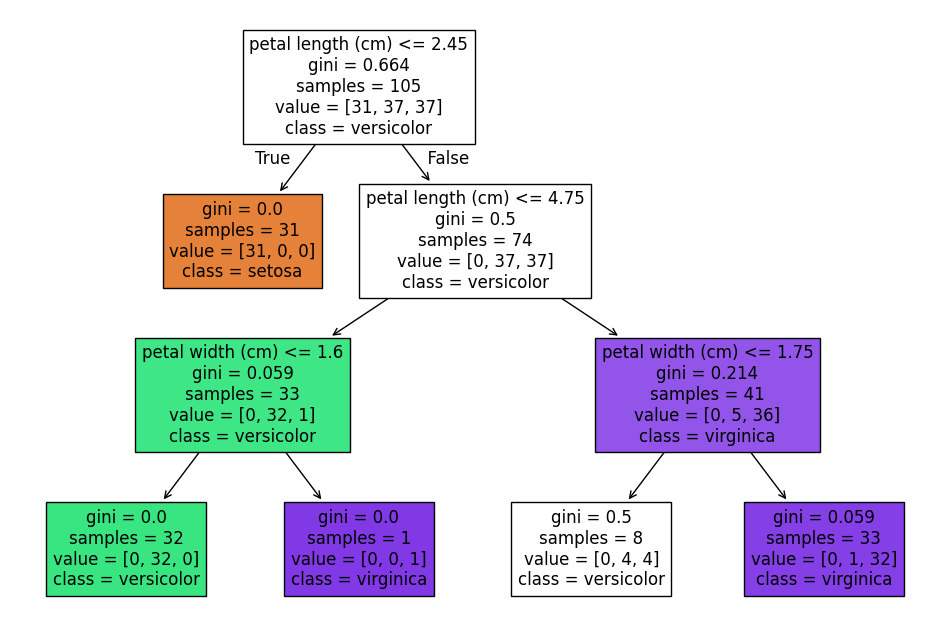

In [1]:
from sklearn.datasets import load_iris
from sklearn import tree
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score
from matplotlib import pyplot as plt

# Carregar dados
X, y = load_iris(return_X_y=True)

# Dividir em treino e teste
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.3, random_state=42
)

# Criar e treinar a árvore
clf = tree.DecisionTreeClassifier(max_depth=3, random_state=42)
clf.fit(X_train, y_train)

# Predizer e avaliar
y_pred = clf.predict(X_test)
print(f"Acurácia: {accuracy_score(y_test, y_pred):.3f}")

# Desenhar a árvore
plt.figure(figsize=(12, 8))
tree.plot_tree(
    clf,
    filled=True,  # Colorir os nós com base na classe majoritária
    feature_names=load_iris().feature_names,  # Nome das variáveis de entrada
    class_names=load_iris().target_names  # Nome das classes de saída
)
plt.show()

### Atributos Categóricos

A implementação da árvore do scikit-learn não suporta categóricos, então é necessário transformá-los em representações numéricas como o One-Hot Encoding.


**Atenção**: Codificação ordinal (atribuir 0, 1, 2 a categorias) é inadequada, pois a árvore interpretará os valores como uma escala numérica, criando divisões como `categoria <= 1.5` que não fazem sentido semântico.

### Valores Ausentes

A implementação do scikit-learn não lida nativamente com valores ausentes em árvores de decisão. A estratégia recomendada é a **imputação** — preencher valores ausentes com a média, mediana, moda ou algum valor constante antes do treinamento.

```python
from sklearn.impute import SimpleImputer

imputer = SimpleImputer(strategy='mean')
X_imputed = imputer.fit_transform(X)
```

### Principais Parâmetros

Estes são os principais parâmetros usados para criar um `DecisionTreeClassifier`:

- `criterion`: define a função de impureza do modelo. As opções são `'gini'` (padrão) ou `'entropy'`;
- `max_depth`: inteiro que indica a profundidade máxima da árvore. É o principal controle de sobreajuste do modelo. O valor padrão é `None`;
- `min_samples_split`: número mínimo de amostras para dividir um nó interno. O valor padrão é 2.
- `class_weight`: pesos associados às classes, no formato `{rótulo_da_classe: peso}`. Se igual `None`, assume-se que todas as classes possuem peso igual a um. A opção `balanced` utiliza os valores de `y` para ajustar automaticamente os pesos de forma inversamente proporcional às frequências das classes nos dados de entrada;
- `ccp_alpha`: parâmetro de complexidade da poda.



## Processo de Poda

A poda (*pruning*) é uma técnica para reduzir o tamanho da árvore e combater o sobreajuste. O objetivo é remover ramos que não contribuem significativamente para a capacidade preditiva do modelo, mantendo apenas as divisões que generalizam bem.

### Como Funciona no scikit-learn

O scikit-learn implementa **Poda por Complexidade de Custo** (*Cost-Complexity Pruning*), baseada no parâmetro `ccp_alpha` .

O processo funciona da seguinte forma:
1. A árvore é construída até sua profundidade máxima.
2. Para cada subárvore potencial, calcula-se uma medida de custo-complexidade:

$$R_\alpha(T) = R(T) + \alpha |T|$$

Onde $R(T)$ é o erro de classificação da árvore $T$, $|T|$ é o número de folhas, e $\alpha$ controla o trade-off entre erro e complexidade .

3. Valores maiores de `ccp_alpha` intensisificam a poda, o que resulta em árvores menos profundas. O valor ótimo pode ser encontrado por validação cruzada.

## Exemplo numérico

Para ilustrar o funcionamento da poda por complexidade de custo, considere uma árvore de classificação já treinada, com 100 amostras no conjunto de treinamento, e três subárvores candidatas:

- $T_1$​ (árvore completa): 8 folhas, 12 erros de classificação.
- $T_2$​ (subárvore podada): 5 folhas, 14 erros.
- $T_3$​ (subárvore mais podada): 3 folhas, 18 erros.

A função de custo-complexidade é:

$$R_\alpha(T) = R(T) + \alpha |T|$$

Como estamos trabalhando com 100 amostras, a taxa de erro $R(T)$ é obtida dividindo o número de erros pelo total de amostras:

- $R(T_1) = \frac{12}{100} = 0{,}12$
- $R(T_2) = \frac{14}{100} = 0{,}14$
- $R(T_3) = \frac{18}{100} = 0{,}18$

**Cenário 1**: $\alpha=0$ (sem penalização por complexidade)

| Árvore | $$R(T)$$ | $$|T|$$ | $$R_\alpha(T) = R(T) + 0 \cdot |T|$$ |
|:------:|:--------:|:-----:|:----------------------------------:|
| $T_1$  | 0,12     | 8     | **0,12**   |
| $T_2$  | 0,14     | 5     | 0,14   |
| $T_3$​  | 0,18     | 3     | 0,18   |

Com $\alpha = 0$, a árvore completa $T_1$ é escolhida, pois tem o menor erro. Isso corresponde a não podar a árvore.

**Cenário 2**: $\alpha = 0{,}01$ (penalização leve)

| Árvore | $$R(T)$$ | $$|T|$$ | $$R_\alpha(T) = R(T) + 0{,}01 \cdot |T|$$ |
|:------:|:--------:|:-----:|:----------------------------------:|
| $T_1$ | 0,12 | 8 | 0,20 |
| $T_2$ | 0,14 | 5 | **0,19** |
| $T_3$​ | 0,18 | 3 | 0,21 |

Com $\alpha = 0{,}01$, a árvore $T_2$ passa a ter o menor custo-complexidade. A penalização por ter 8 folhas superou a pequena vantagem de erro de $T_1$. O resultado é uma poda parcial.

**Cenário 3**: $\alpha = 0{,}03$ (penalização forte)

| Árvore | $$R(T)$$ | $$|T|$$ | $$R_\alpha(T) = R(T) + 0{,}03 \cdot |T|$$ |
|:------:|:--------:|:-----:|:----------------------------------:|
| $T_1$ | 0,12 | 8 | 0,36 |
| $T_2$ | 0,14 | 5 | 0,29 |
| $T_3$​ | 0,18 | 3 | **0,27** |

Com $\alpha = 0{,}03$, a árvore mais simples $T_3$​ vence, pois a economia em complexidade compensa o aumento do erro. O resultado é uma poda mais intensa.

O exemplo mostra que o parâmetro $\alpha$ controla diretamente o trade-off entre erro de classificação e complexidade da árvore:

- $\alpha$ pequeno → favorece árvores maiores (menor viés, maior variância).
- $\alpha$ grande → favorece árvores menores (maior viés, menor variância).

## Exemplo Prático

In [7]:
from sklearn.tree import DecisionTreeClassifier
import pandas as pd

# Geração de valores para ccp_alpha e das respectivas árvores e subárvores.
# A função cost_complexity_pruning_path cria uma árvore totalmente crescida e
# calcula um caminho de subárvores e seus respectivos valores de ccp_alpha.
clf = DecisionTreeClassifier(random_state=42)
path = clf.cost_complexity_pruning_path(X_train, y_train)

# Avaliação para os diferentes valores de ccp_alpha
scores = []
for alpha in path.ccp_alphas:
    clf = DecisionTreeClassifier(ccp_alpha=alpha, random_state=42)
    clf.fit(X_train, y_train)
    y_pred_train = clf.predict(X_train)
    y_pred_test = clf.predict(X_test)
    train_score = accuracy_score(y_train, y_train)
    test_score = accuracy_score(y_test, y_pred_test)
    scores.append([alpha, clf.get_depth(), clf.get_n_leaves(), train_score, test_score])

df = pd.DataFrame(scores, columns=["ccp_alpha", "profundidade", "folhas", "acc (treino)", "acc (teste)"])
df.sort_values(by="acc (teste)", ascending=False, inplace=True)
display(df)


,ccp_alpha,profundidade,folhas,acc (treino),acc (teste)
0,0.000000,6,10,1.0,1.000000
1,0.009235,6,8,1.0,1.000000
2,0.012698,4,6,1.0,1.000000
3,0.012698,3,5,1.0,1.000000
4,0.018470,3,4,1.0,1.000000
5,0.027058,2,3,1.0,0.977778
6,0.250287,1,2,1.0,0.711111
7,0.312109,0,1,1.0,0.288889


## Dicas de Uso Prático

1. **Comece simples**: Use `max_depth=3` como valor inicial para visualizar a árvore e entender como ela se ajusta aos dados .

2. **Controle a profundidade**: O número de amostras necessárias para popular a árvore dobra a cada nível. `max_depth` é a ferramenta mais direta contra sobreajuste .

3. **Use `min_samples_leaf`**: Valores como 5 ou 10 garantem que cada folha tenha um número mínimo de amostras, evitando decisões baseadas em poucos exemplos .

4. **Visualize a árvore**: Aproveite a interpretabilidade. Use `export_graphviz` ou `plot_tree` para inspecionar as regras aprendidas e verificar se fazem sentido .

5. **Balanceie as classes**: Dados desbalanceados podem enviesar a árvore para a classe majoritária. Use `class_weight='balanced'` ou técnicas de reamostragem .

6. **Considere redução de dimensionalidade**: Árvores tendem a sobreajustar com muitas features. PCA ou seleção de features podem ajudar.

## Outras Implementações

- **rpart** (linguagem R): é a implementação mais fiel e tradicional do algoritmo CART. Ela gerencia variáveis categóricas nativamente, testando partições de categorias de forma otimizada para encontrar a divisão binária ideal.
- **TDF** (Python e C++): é uma biblioteca desenvolvida pelo Google que contém uma implementação do CART que aceita strings/categorias nativamente.


## Referências

- Google for Developers. **Árvores de decisão**". Disponível em <https://developers.google.com/machine-learning/decision-forests/decision-trees?hl=pt-br>.
- Scikit-learn Documentation. **1.10. Decision Trees**. Disponível em <https://scikit-learn.org/stable/modules/tree.html>.
- Scikit-learn Documentation. **DecisionTreeClassifier**. Disponível em <https://scikit-learn.org/stable/modules/generated/sklearn.tree.DecisionTreeClassifier.html>.
